## Import libraries

In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Common function: plot training graphs

In [6]:
def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

# 2A. CNN – CIFAR-10 image classification

**Dataset:** 32 × 32 RGB images, 10 classes.

## Stage 1: Loading and preprocessing the image data

In [7]:
df = pd.read_csv('dataset/fnn_cnn/CIFAR10/cifar-10.csv')

x = df.drop('label', axis=1)
x = x.to_numpy().reshape(-1, 32, 32, 3)
y = df['label'].values

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [8]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


## Stage 2: Defining the model architecture

In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

E0000 00:00:1793563843.030390  205712 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Training the model

In [10]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/10


W0000 00:00:1793563853.553455  205712 cpu_allocator_impl.cc:82] Allocation of 491520000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.3693 - loss: 1.7545 - val_accuracy: 0.4465 - val_loss: 1.5471
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.4881 - loss: 1.4549 - val_accuracy: 0.5047 - val_loss: 1.4128
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.5304 - loss: 1.3359 - val_accuracy: 0.5419 - val_loss: 1.3071
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.5580 - loss: 1.2562 - val_accuracy: 0.5578 - val_loss: 1.2738
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.5844 - loss: 1.1850 - val_accuracy: 0.5866 - val_loss: 1.1914
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.6033 - loss: 1.1343 - val_accuracy: 0.5946 - val_loss: 1.1650
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.6228 - loss: 1.0850 - val_accuracy: 0.5955 - val_loss: 1.1595
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.6407 - loss: 1.0345 - val_accurac

## Stage 4: Estimating model performance

In [11]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6170 - loss: 1.1148
Test Loss: 1.1147782802581787
Test Accuracy: 0.6169999837875366


### Training graphs

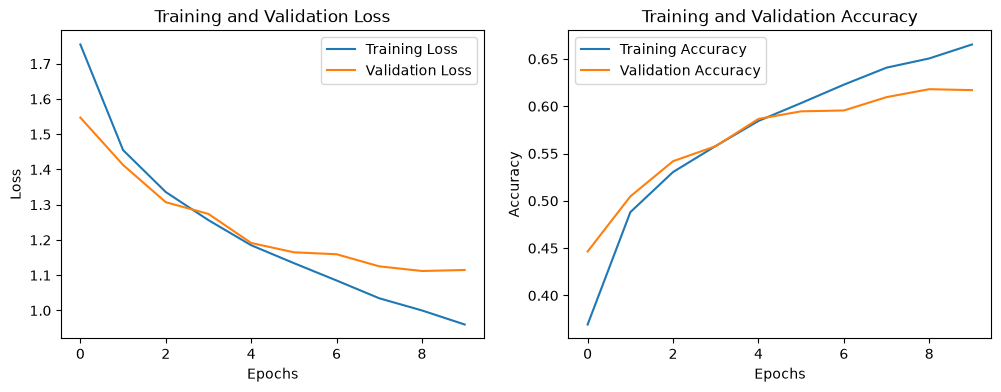

In [12]:
plot_history(history)

# 2B. CNN – MNIST handwritten digit classification

**Dataset:** 28 × 28 grayscale images, 10 classes.

## Stage 1: Loading and preprocessing the image data

In [16]:
df_train = pd.read_csv("dataset/fnn_cnn/hand/mnist_train.csv")
df_test = pd.read_csv("dataset/fnn_cnn/hand/mnist_test.csv")

x_train = df_train.drop('label', axis=1).to_numpy()
y_train = df_train['label'].values

x_test = df_test.drop('label', axis=1).to_numpy()
y_test = df_test['label'].values

In [17]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 28, 28, 1)
Testing data: (10000, 28, 28, 1)


## Stage 2: Defining the model architecture

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Training the model

In [20]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/5
  7/469 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9766 - loss: 0.0797

W0000 00:00:1793564098.663895  205712 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9820 - loss: 0.0585 - val_accuracy: 0.9864 - val_loss: 0.0419
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9876 - loss: 0.0397 - val_accuracy: 0.9891 - val_loss: 0.0339
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9911 - loss: 0.0296 - val_accuracy: 0.9874 - val_loss: 0.0377
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9925 - loss: 0.0236 - val_accuracy: 0.9875 - val_loss: 0.0368
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9936 - loss: 0.0193 - val_accuracy: 0.9905 - val_loss: 0.0293


## Stage 4: Estimating model performance

In [21]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9905 - loss: 0.0293
Test Loss: 0.02927040122449398
Test Accuracy: 0.9904999732971191


### Training graphs

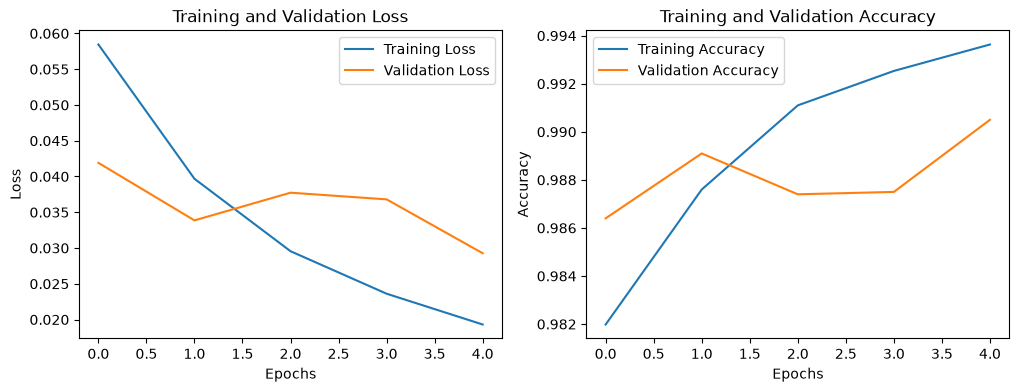

In [22]:
plot_history(history)

# 2C. CNN – Sign Language MNIST classification

**Dataset:** 28 × 28 grayscale images, 24 classes.

Download `sign_mnist_train.csv` and `sign_mnist_test.csv` and place them in the same folder as this notebook. Each CSV should contain a `label` column and 784 pixel columns.

## Stage 1: Loading and preprocessing the image data

In [23]:
train_data = pd.read_csv('dataset/fnn_cnn/sign/sign_mnist_train.csv')
test_data = pd.read_csv('dataset/fnn_cnn/sign/sign_mnist_test.csv')

x_train = train_data.drop('label', axis=1).to_numpy()
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).to_numpy()
y_test = test_data['label'].values

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [24]:
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Number of classes:", len(encoder.classes_))

Training data: (27455, 28, 28, 1)
Testing data: (7172, 28, 28, 1)
Number of classes: 24


## Stage 2: Defining the model architecture

In [25]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(24, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

## Stage 3: Training the model

In [26]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8748 - loss: 0.8074 - val_accuracy: 0.8610 - val_loss: 0.5450
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9866 - loss: 0.0458 - val_accuracy: 0.8802 - val_loss: 0.5345
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9906 - loss: 0.0320 - val_accuracy: 0.8358 - val_loss: 0.8454
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9895 - loss: 0.0351 - val_accuracy: 0.8681 - val_loss: 0.7431
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9958 - loss: 0.0137 - val_accuracy: 0.8780 - val_loss: 0.6432
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9970 - loss: 0.0093 - val_accuracy: 0.8631 - val_loss: 0.7106
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9924 - loss: 0.0298 - val_accuracy: 0.9216 - val_loss: 0.5484
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 1.0000 - loss: 1.9303e-04 - val_accuracy

## Stage 4: Estimating model performance

In [27]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9253 - loss: 0.4715
Test Loss: 0.47146135568618774
Test Accuracy: 0.9252648949623108


### Training graphs

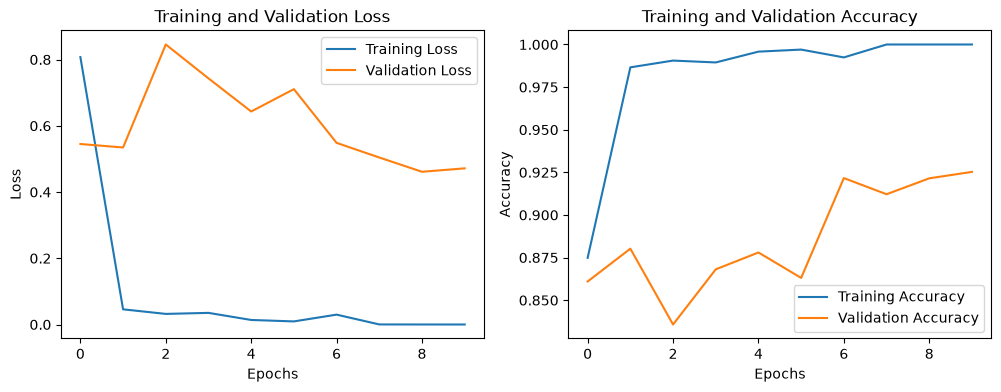

In [28]:
plot_history(history)